# Predicting How Long Customers Rent DVDs

This notebook predicts how many days a customer keeps a rented DVD, using regression models. It started as a DataCamp project, and I extended it by exploring the price columns, selecting features with a Lasso, and comparing four tuned models with cross-validation.

**A note on AI use:** The code, the analysis, and the conclusions are my own work. I used AI (Claude) as a writing aid, to help me phrase my findings clearly and to tidy the notebook's formatting and comments.

## Context

![dvd_image](dvd_image.jpg)

A DVD rental company needs your help! They want to figure out how many days a customer will rent a DVD for based on some features and has approached you for help. They want you to try out some regression models which will help predict the number of days a customer will rent a DVD for. The company wants a model which yeilds a MSE of 3 or less on a test set. The model you make will help the company become more efficient inventory planning.

The data they provided is in the csv file `data/rental_info.csv`. It has the following features:
- `"rental_date"`: The date (and time) the customer rents the DVD.
- `"return_date"`: The date (and time) the customer returns the DVD.
- `"amount"`: The amount paid by the customer for renting the DVD.
- `"amount_2"`: The square of `"amount"`.
- `"rental_rate"`: The rate at which the DVD is rented for.
- `"rental_rate_2"`: The square of `"rental_rate"`.
- `"release_year"`: The year the movie being rented was released.
- `"length"`: Lenght of the movie being rented, in minuites.
- `"length_2"`: The square of `"length"`.
- `"replacement_cost"`: The amount it will cost the company to replace the DVD.
- `"special_features"`: Any special features, for example trailers/deleted scenes that the DVD also has.
- `"NC-17"`, `"PG"`, `"PG-13"`, `"R"`: These columns are dummy variables of the rating of the movie. It takes the value 1 if the move is rated as the column name and 0 otherwise. For your convinience, the reference dummy has already been dropped.

## Goal

Predict `rental_length_days` with a **mean squared error (MSE) below 3** on a test set. The brief asks for:
- the target `rental_length_days` and the dummy columns `deleted_scenes` and `behind_the_scenes`,
- `X` (features without leaking columns) and `y` (target), split into `X_train`, `X_test`, `y_train`, `y_test` with 20% of the data in the test set,
- `random_state=9` whenever there is randomness,
- the recommended model as `best_model` and its test MSE as `best_mse`.

## Plan

1. Setup
2. Load and inspect the data
3. Create the target and the dummy variables
4. Explore the data
5. Choose the features and split the data
6. Select features with a Lasso
7. Train and tune the models
8. Check the best model
9. Conclusion

## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import mean_squared_error
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LassoCV, LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# Import any additional modules and start coding below
RANDOM_STATE = 9  # required by the brief, used every time there is randomness
TEST_SIZE = 0.2  # 20% of the data goes to the test set
CV_FOLDS = 5  # number of folds for cross-validation

BLUE = "#2a78d6"  # main colour of the figures
ORANGE = "#eb6834"  # colour used to highlight

## 2. Load and inspect the data

In [2]:
rental_info = pd.read_csv("data/rental_info.csv")
rental_info.head()

,rental_date,return_date,amount,release_year,rental_rate,length,replacement_cost,special_features,NC-17,PG,PG-13,R,amount_2,length_2,rental_rate_2
0,2005-05-25 02:54:33+00:00,2005-05-28 23:40:33+00:00,2.99,2005.0,2.99,126.0,16.99,"{Trailers,""Behind the Scenes""}",0,0,0,1,8.9401,15876.0,8.9401
1,2005-06-15 23:19:16+00:00,2005-06-18 19:24:16+00:00,2.99,2005.0,2.99,126.0,16.99,"{Trailers,""Behind the Scenes""}",0,0,0,1,8.9401,15876.0,8.9401
2,2005-07-10 04:27:45+00:00,2005-07-17 10:11:45+00:00,2.99,2005.0,2.99,126.0,16.99,"{Trailers,""Behind the Scenes""}",0,0,0,1,8.9401,15876.0,8.9401
3,2005-07-31 12:06:41+00:00,2005-08-02 14:30:41+00:00,2.99,2005.0,2.99,126.0,16.99,"{Trailers,""Behind the Scenes""}",0,0,0,1,8.9401,15876.0,8.9401
4,2005-08-19 12:30:04+00:00,2005-08-23 13:35:04+00:00,2.99,2005.0,2.99,126.0,16.99,"{Trailers,""Behind the Scenes""}",0,0,0,1,8.9401,15876.0,8.9401


In [3]:
rental_info.info()

<class 'pandas.DataFrame'>
RangeIndex: 15861 entries, 0 to 15860
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   rental_date       15861 non-null  str    
 1   return_date       15861 non-null  str    
 2   amount            15861 non-null  float64
 3   release_year      15861 non-null  float64
 4   rental_rate       15861 non-null  float64
 5   length            15861 non-null  float64
 6   replacement_cost  15861 non-null  float64
 7   special_features  15861 non-null  str    
 8   NC-17             15861 non-null  int64  
 9   PG                15861 non-null  int64  
 10  PG-13             15861 non-null  int64  
 11  R                 15861 non-null  int64  
 12  amount_2          15861 non-null  float64
 13  length_2          15861 non-null  float64
 14  rental_rate_2     15861 non-null  float64
dtypes: float64(8), int64(4), str(3)
memory usage: 3.1 MB


In [4]:
print("Missing values:", rental_info.isna().sum().sum())
print("Duplicated rows:", rental_info.duplicated().sum())

Missing values: 0
Duplicated rows: 0


The dataset has 15,861 rentals and 15 columns, with no missing values and no duplicated rows, so there is nothing to clean. `rental_date`, `return_date` and `special_features` are text, which I handle in the next step. The four rating columns (`NC-17`, `PG`, `PG-13`, `R`) are already dummy variables, and `amount_2`, `length_2` and `rental_rate_2` are the squares of their corresponding columns.

## 3. Create the target and the dummy variables

### 3.1 Target

The rental length is the time between `rental_date` and `return_date`. That is why I convert both columns to dates, subtract them, and keep the number of **whole days** with `.dt.days`.

In [5]:
rental_info["rental_date"] = pd.to_datetime(rental_info["rental_date"])  # convert the text to a date
rental_info["return_date"] = pd.to_datetime(rental_info["return_date"])

rental_info["rental_length_days"] = (rental_info["return_date"] - rental_info["rental_date"]).dt.days  # number of whole days between rental and return
rental_info[["rental_date", "return_date", "rental_length_days"]].head()

,rental_date,return_date,rental_length_days
0,2005-05-25 02:54:33+00:00,2005-05-28 23:40:33+00:00,3
1,2005-06-15 23:19:16+00:00,2005-06-18 19:24:16+00:00,2
2,2005-07-10 04:27:45+00:00,2005-07-17 10:11:45+00:00,7
3,2005-07-31 12:06:41+00:00,2005-08-02 14:30:41+00:00,2
4,2005-08-19 12:30:04+00:00,2005-08-23 13:35:04+00:00,4


### 3.2 Dummy variables

`special_features` column is a text that lists all the extras of a DVD, for example `{Trailers,"Behind the Scenes"}`. A model needs numbers, so I need to create two dummy 0/1 columns: 1 when the text contains the feature, 0 otherwise.

In [6]:
rental_info["deleted_scenes"] = rental_info["special_features"].str.contains("Deleted Scenes").astype(int)  # 1 if the text contains "Deleted Scenes", else 0
rental_info["behind_the_scenes"] = rental_info["special_features"].str.contains("Behind the Scenes").astype(int)  # 1 if the text contains "Behind the Scenes", else 0

rental_info[["special_features", "deleted_scenes", "behind_the_scenes"]].drop_duplicates().head(6)  # check a few different values

,special_features,deleted_scenes,behind_the_scenes
0,"{Trailers,""Behind the Scenes""}",0,1
53,{Trailers},0,0
83,"{Commentaries,""Behind the Scenes""}",0,1
93,"{Trailers,Commentaries}",0,0
119,"{""Deleted Scenes"",""Behind the Scenes""}",1,1
135,"{Commentaries,""Deleted Scenes"",""Behind the Sce...",1,1


## 4. Explore the data

In [7]:
rental_info.describe().round(2)  # summary statistics of the numeric columns

,amount,release_year,rental_rate,length,replacement_cost,NC-17,PG,PG-13,R,amount_2,length_2,rental_rate_2,rental_length_days,deleted_scenes,behind_the_scenes
count,15861.00,15861.00,15861.00,15861.00,15861.00,15861.0,15861.0,15861.00,15861.0,15861.00,15861.00,15861.00,15861.00,15861.0,15861.00
mean,4.22,2006.89,2.94,114.99,20.22,0.2,0.2,0.22,0.2,23.36,14832.84,11.39,4.53,0.5,0.54
std,2.36,2.03,1.65,40.11,6.08,0.4,0.4,0.42,0.4,23.50,9393.43,10.01,2.64,0.5,0.50
min,0.99,2004.00,0.99,46.00,9.99,0.0,0.0,0.00,0.0,0.98,2116.00,0.98,0.00,0.0,0.00
25%,2.99,2005.00,0.99,81.00,14.99,0.0,0.0,0.00,0.0,8.94,6561.00,0.98,2.00,0.0,0.00
50%,3.99,2007.00,2.99,114.00,20.99,0.0,0.0,0.00,0.0,15.92,12996.00,8.94,5.00,0.0,1.00
75%,4.99,2009.00,4.99,148.00,25.99,0.0,0.0,0.00,0.0,24.90,21904.00,24.90,7.00,1.0,1.00
max,11.99,2010.00,4.99,185.00,29.99,1.0,1.0,1.00,1.0,143.76,34225.00,24.90,9.00,1.0,1.00


`rental_length_days` goes from 0 to 9 days with a mean of 4.53. `rental_rate` goes from 0.99 to 4.99, but `amount` goes up to 11.99: some customers pay more than the standard rate.

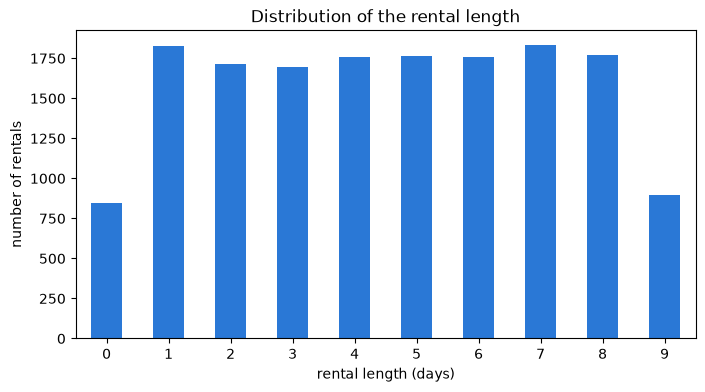

In [8]:
length_counts = rental_info["rental_length_days"].value_counts().sort_index()  # number of rentals for each length of rental (in days)

length_counts.plot(kind="bar", color=BLUE, figsize=(8, 4))
plt.title("Distribution of the rental length")
plt.xlabel("rental length (days)")
plt.ylabel("number of rentals")
plt.xticks(rotation=0)
plt.show()

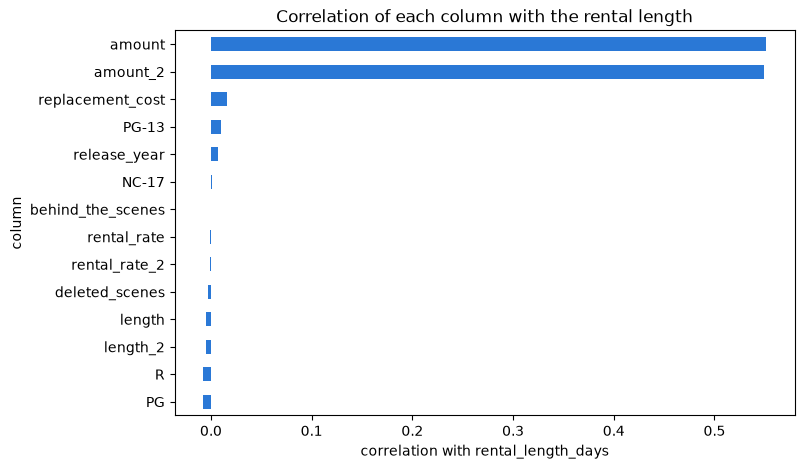

In [9]:
correlations = (
    rental_info.drop(columns=["rental_date", "return_date", "special_features"])  # keep the numeric columns only
    .corr()["rental_length_days"]  # correlation of each column with the target variable
    .drop("rental_length_days") # drop the correlation of the target variable with itself
    .sort_values()
)

correlations.plot(kind="barh", color=BLUE, figsize=(8, 5))
plt.title("Correlation of each column with the rental length")
plt.xlabel("correlation with rental_length_days")
plt.ylabel("column")
plt.show()

- The rental lengths from 1 to 8 days are about equally frequent, while 0 and 9 days are about half as frequent.
- Only `amount` and `amount_2` are clearly linked to the rental length (correlation of about 0.55). All the other columns, including the two dummies I created, have a correlation between -0.01 and 0.02, which is close to nothing.

### Why is `amount` linked to the rental length?

`amount` is what the customer paid and `rental_rate` is the standard price of the DVD. I look at the difference between the two for each rental length.

In [10]:
extra_paid = (rental_info["amount"] - rental_info["rental_rate"]).round(2)  # what the customer paid above the rental rate

extra_by_length = pd.DataFrame({
    "mean_extra_paid": extra_paid.groupby(rental_info["rental_length_days"]).mean(),  # average extra for each rental length
    "share_with_extra": (extra_paid > 0).groupby(rental_info["rental_length_days"]).mean(),  # share of rentals that paid an extra
})
extra_by_length.round(2)

,mean_extra_paid,share_with_extra
rental_length_days,,
0,0.00,0.00
1,0.00,0.00
2,0.00,0.00
3,0.10,0.10
4,0.44,0.32
5,0.96,0.52
6,1.63,0.73
7,2.53,0.91
8,3.56,1.00


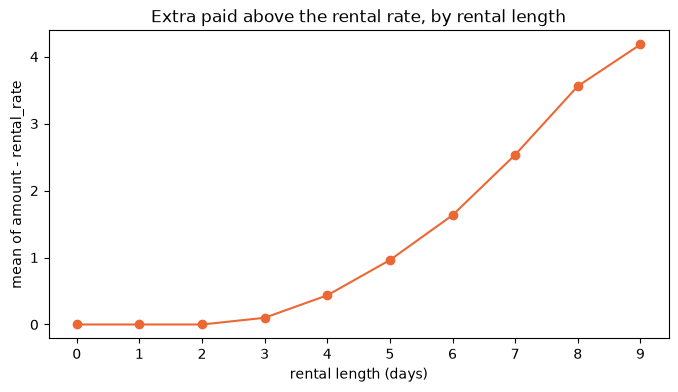

In [11]:
extra_by_length["mean_extra_paid"].plot(marker="o", color=ORANGE, figsize=(8, 4))
plt.title("Extra paid above the rental rate, by rental length")
plt.xlabel("rental length (days)")
plt.ylabel("mean of amount - rental_rate")
plt.xticks(range(10))
plt.show()

- Up to 2 days, nobody pays more than the rental rate.
- From 3 days, an extra appears and grows. The mean extra goes from 0.10 at 3 days to 4.18 at 9 days.

This looks like a **late fee**, which is my interpretation since the data does not say it. If so, `amount` is only known once the DVD is back, which is also when the rental length is known. This is called a column that **leaks** information about the target.

**Why I keep it anyway:** 

- The late fee is only my interpretation. The extra paid could also come from something else, for example a different price for some customers or periods, and then amount would be a normal feature. 
  
- The brief also lists amount as a normal feature, and it is the only column clearly linked to the rental length: without it, the goal of an MSE below 3 would probably be out of reach. 

## 5. Choose the features and split the data

I remove from `X`:
- `rental_date` and `return_date`, because the target is computed from them,
- `special_features`, because it is text and is replaced by the two dummies,
- `rental_length_days`, the target itself.

**My decision on `amount`:** I keep `amount` and `amount_2`. In my opinion, there is a chance that they partly leak the target (see above), but they are not a copy of it, and they are the only columns clearly linked to it. I just have to keep this in mind when reading the results, and come back to it when interpreting the conclusion.

Then I split the data: 80% to train the models, 20% to test them, with `random_state=9`.

In [12]:
X = rental_info.drop(columns=["rental_date", "return_date", "special_features", "rental_length_days"])  # the features
y = rental_info["rental_length_days"]  # the target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE)  # 80% train, 20% test

print("Features:", X.columns.tolist())
print("\nTrain set:", X_train.shape)
print("Test set:", X_test.shape)

Features: ['amount', 'release_year', 'rental_rate', 'length', 'replacement_cost', 'NC-17', 'PG', 'PG-13', 'R', 'amount_2', 'length_2', 'rental_rate_2', 'deleted_scenes', 'behind_the_scenes']

Train set: (12688, 14)
Test set: (3173, 14)


The train set has 12,688 rentals and the test set 3,173. `X` has 14 features.

## 6. Select features with a Lasso

A Lasso is a linear regression with a penalty: the bigger the penalty, the more coefficients are pushed to exactly 0, and those features are dropped.

- The features must be on the same scale, so I put a `StandardScaler` before the Lasso with `make_pipeline`.
- `LassoCV` chooses the penalty (`alpha`) with 5-fold cross-validation.
- Everything is fitted on the train set only, so the test set does not influence the choice.

Penalty chosen (alpha): 0.0014


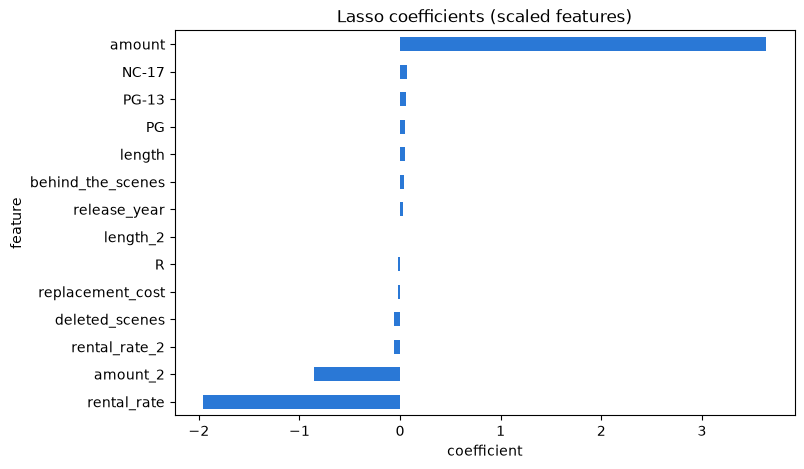

In [13]:
lasso_pipeline = make_pipeline(StandardScaler(), LassoCV(cv=CV_FOLDS, random_state=RANDOM_STATE))  # scale the features, then a Lasso whose penalty is chosen by cross-validation
lasso_pipeline.fit(X_train, y_train)  # fitted on the train set only

lasso = lasso_pipeline.named_steps["lassocv"]  # get the Lasso step out of the pipeline
lasso_coefficients = pd.Series(lasso.coef_, index=X_train.columns)  # one coefficient per feature
print("Penalty chosen (alpha):", round(lasso.alpha_, 4))

lasso_coefficients.sort_values().plot(kind="barh", color=BLUE, figsize=(8, 5))
plt.title("Lasso coefficients (scaled features)")
plt.xlabel("coefficient")
plt.ylabel("feature")
plt.show()

In [14]:
selected_features = lasso_coefficients[lasso_coefficients != 0].index.tolist()  # features with a coefficient different from 0

X_train_selected = X_train[selected_features]
X_test_selected = X_test[selected_features]

print("Features removed:", [feature for feature in X_train.columns if feature not in selected_features])
print("Number of features kept:", len(selected_features))

Features removed: ['length_2']
Number of features kept: 13


- The penalty chosen by cross-validation is very small (alpha = 0.0014), so the Lasso only drops `length_2`. I keep the other 13 features.
- `amount` (3.64), `rental_rate` (-1.96) and `amount_2` (-0.85) have by far the largest coefficients. All the others are below 0.07, close to zero.


Here the Lasso only removes `length_2` due to the small penalty chosen, so the selection has almost no effect and could be removed, and the tree models also choose their own features at each split. Feature selection with a Lasso is more useful on larger datasets with many features, where some of them add only noise. However, I choose to keep it as it is part of the process.

## 7. Train and tune the models

I compare four models. 
- Linear Regression
- Decision Tree Regressor
- Random Forest Regressor
- Gradient Boosting Regressor
  
Two of them are **ensemble methods**: a random forest averages many trees trained on bootstrap samples (bagging), and gradient boosting adds trees one after the other, each one correcting the errors left by the previous ones.

First, we set a **baseline** as a naive model, predicting the **mean rental length** of the train set for every rental without using any feature. A useful model must do clearly better than this. It shows why an MSE of 3 is a good objective.

Here it only uses `y_train`, the train target, takes its mean, and repeats that number once per test rental. It shows the error without any information from X

In [15]:
baseline_predictions = np.full(len(y_test), y_train.mean())  # predict the mean rental length of the train set for every test rental over the length of the test set

baseline_mse = mean_squared_error(y_test, baseline_predictions)
print("Baseline test MSE:", round(baseline_mse, 3))

Baseline test MSE: 7.1


In [16]:
models = {  # instantiate the four models to compare in a dictionary
    "Linear regression": LinearRegression(),
    "Decision tree": DecisionTreeRegressor(random_state=RANDOM_STATE),
    "Random forest": RandomForestRegressor(random_state=RANDOM_STATE),
    "Gradient boosting": GradientBoostingRegressor(random_state=RANDOM_STATE),
}

param_grids = {  # the hyperparameter values to try for each model
    "Linear regression": {},  # nothing to tune
    "Decision tree": {"max_depth": [5, 10, None], "min_samples_leaf": [1, 5, 10]},
    "Random forest": {"n_estimators": [100, 200], "max_depth": [10, 20, None]},
    "Gradient boosting": {"n_estimators": [100, 300], "learning_rate": [0.1, 0.2], "max_depth": [3, 5]},
}

In [17]:
tuned_models = {}
results = []

for model_name in models: # loop through the four models to tune their hyperparameters
    grid = GridSearchCV(estimator=models[model_name], 
                        param_grid=param_grids[model_name], 
                        cv=CV_FOLDS,
                        scoring="neg_mean_squared_error", 
                        n_jobs=-1)  # try every model and parameter combination with 5-fold cross-validation
    
    grid.fit(X_train_selected, y_train)  # the best combination is then refitted on the whole train set

    tuned_models[model_name] = grid.best_estimator_ # store the best model for each type in a dictionary
    print(model_name, "- best hyperparameters:", grid.best_params_)

    y_pred = grid.predict(X_test_selected)  # predictions of the best combination on the test set

    results.append({
        "Model": model_name,
        "CV MSE": -grid.best_score_,  # the score is a negative MSE, so I flip the sign
        "Test MSE": mean_squared_error(y_test, y_pred),
    })

results_table = pd.DataFrame(results).set_index("Model")
results_table.round(3)

Linear regression - best hyperparameters: {}


Decision tree - best hyperparameters: {'max_depth': None, 'min_samples_leaf': 1}


Random forest - best hyperparameters: {'max_depth': 20, 'n_estimators': 200}


Gradient boosting - best hyperparameters: {'learning_rate': 0.2, 'max_depth': 5, 'n_estimators': 300}


,CV MSE,Test MSE
Model,,
Linear regression,2.849,2.942
Decision tree,2.281,2.167
Random forest,2.065,2.024
Gradient boosting,1.871,1.892


- All four models are below the target of 3, and far below the baseline (7.10).
  
- Linear regression is only just under 3 (2.942). The extra paid only starts after 2 days, which a straight line probably follows badly.
  
- The three tree models do better, and the two ensembles are the best: random forest 2.024 and gradient boosting 1.892.
  
- I choose the model with the lowest **CV MSE**, not the lowest test MSE, so the test set is not used to choose but only as extra information. Gradient boosting has both the lowest CV MSE (1.871) and the lowest test MSE.
- The choice is made on the CV MSE, and only the test MSE of the chosen model becomes the official result, `best_mse`
  
- Some best values are at the edge of their grid (for example `learning_rate=0.2` and `n_estimators=300` for gradient boosting), so maybe a wider grid could improve the result a little.

In [18]:
best_name = results_table["CV MSE"].idxmin()  # the model with the lowest cross-validation MSE
best_model = tuned_models[best_name]
best_y_pred = best_model.predict(X_test_selected) # predictions of the best model on the test set
best_mse = mean_squared_error(y_test, best_y_pred) # compute the MSE of the best model on the test set

print("Best model:", best_name)
print("Best test MSE:", round(best_mse, 3))

Best model: Gradient boosting
Best test MSE: 1.892


### Is the best model overfitting?

I now compare the error on the train set, the cross-validation error and the test error. A train error much lower than the CV error is a sign of overfitting.

In [19]:
train_mse = mean_squared_error(y_train, best_model.predict(X_train_selected))  # error on the rentals the model has seen

print("Train MSE:", round(train_mse, 3))
print("CV MSE:", round(results_table.loc[best_name, "CV MSE"], 3))
print("Test MSE:", round(best_mse, 3))

Train MSE: 1.484
CV MSE: 1.871
Test MSE: 1.892


The train MSE (1.484) is lower than the CV MSE (1.871), so the model fits the rentals it has seen a bit better than new ones: there is some overfitting, but not much. The CV MSE and the test MSE (1.892) are very close, so the cross-validation gave a good estimate of the error on new data.

## 8. Check the best model

This MSE number can hide how the errors are spread. 

The MSE is an average over all the test rentals, so it does not show where the model makes its errors: it could be good for short rentals and bad for long ones, and the MSE would not show it. 

So I plot the predictions for each real rental length, to see where the model is accurate and where it is not. Then I look at which features the model uses most.


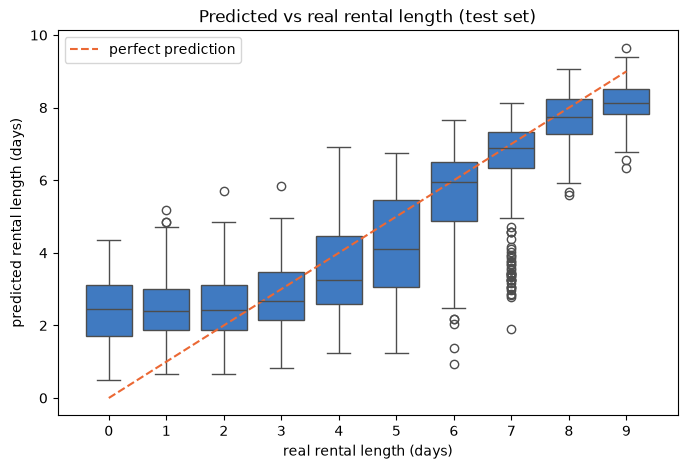

In [20]:
test_predictions = best_model.predict(X_test_selected)

plt.figure(figsize=(8, 5))
sns.boxplot(x=y_test, y=test_predictions, color=BLUE)  # one box of predictions for each real rental length
plt.plot([0, 9], [0, 9], color=ORANGE, linestyle="--", label="perfect prediction")
plt.title("Predicted vs real rental length (test set)")
plt.xlabel("real rental length (days)")
plt.ylabel("predicted rental length (days)")
plt.legend()
plt.show()

The dashed line shows a perfect prediction. A box above the line means the model overestimates those rentals, a box below means it underestimates them, and a tall box means the predictions are spread out.

- Rentals of 0, 1 and 2 days all get about the same prediction, between 2 and 3 days. They pay the same price (no extra), so the model cannot tell them apart.
- The spread is the largest at 4 and 5 days, where only part of the rentals pay an extra.
- The longest rentals (8 and 9 days) are the best predicted, with narrow boxes, but slightly below the real length.

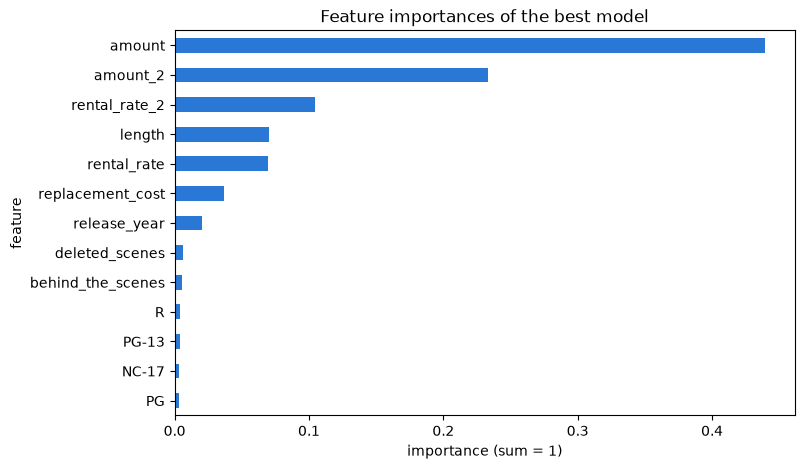

In [21]:
importances = pd.Series(best_model.feature_importances_, index=selected_features)  # how much each feature helped the trees

importances.sort_values().plot(kind="barh", color=BLUE, figsize=(8, 5))
plt.title("Feature importances of the best model")
plt.xlabel("importance (sum = 1)")
plt.ylabel("feature")
plt.show()

`amount` (0.439) and `amount_2` (0.233) make up about two thirds of the importance. The rental rate columns and `length` come next, and the special features and ratings are close to 0. The model relies mostly on the price paid.

## 9. Conclusion

In [22]:
summary = results_table[["CV MSE", "Test MSE"]].copy()
summary.loc["Baseline (mean)"] = [np.nan, baseline_mse]  # add the baseline, which has no cross-validation
summary["Test RMSE (in days)"] = np.sqrt(summary["Test MSE"])  # square root of the MSE, back in days
summary["Below 3"] = summary["Test MSE"] < 3
summary.sort_values("Test MSE").round(3)

,CV MSE,Test MSE,Test RMSE (in days),Below 3
Model,,,,
Gradient boosting,1.871,1.892,1.376,True
Random forest,2.065,2.024,1.423,True
Decision tree,2.281,2.167,1.472,True
Linear regression,2.849,2.942,1.715,True
Baseline (mean),NaN,7.100,2.665,False


**What the results show**

- The recommended model is **gradient boosting** (`best_model`), with a test MSE of **1.892** (`best_mse`), below the target of 3. Its RMSE of 1.38 days is the typical size of an error.
- All four models reach the target. The ensemble methods (gradient boosting and random forest) do best, and linear regression is only just under 3.
- The predictions rely mostly on the price paid (`amount`). The model separates short and long rentals well, but cannot tell apart rentals of 0, 1 and 2 days.

**Limits**

- `amount` seems to include a late fee, which is only known once the DVD is returned. So the model explains rental length from the price paid, but could not predict it at the moment of the rental. I expect a much higher error without `amount`, since all the other columns have a correlation close to 0, but I did not test it in this notebook.
- The results come from one train/test split (`random_state=9`). Small gaps, like the 0.13 between random forest and gradient boosting, could change with another split.
- The parameter grids are small and some better values probably lie at the edge of the lists.